# EDA: correlations

Which quantities move together: across users, across anime, across genres, and between pairs
of anime. Rank (Spearman) correlation is used throughout because almost every quantity here
is heavily skewed.

Inputs: `data/clean/{users,anime}.parquet`, `data/eda/user_stats.parquet`,
`tables/anime_stats.parquet` and `tables/cooccurrence.npz`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from cleaning import config, plotting
from cleaning.plotting import BLUE, MUTED

plotting.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(70)


def spearman(frame: pl.DataFrame) -> np.ndarray:
    ranks = frame.select(pl.all().rank()).to_numpy()
    return np.corrcoef(ranks, rowvar=False)


def heatmap(matrix, labels, title, size=(8, 6.5), annotate=True):
    fig, ax = plt.subplots(figsize=size)
    im = ax.imshow(matrix, cmap=plotting.DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.grid(False)
    if annotate:
        for i in range(len(labels)):
            for j in range(len(labels)):
                if i != j:
                    ax.text(j, i, f"{matrix[i, j]:.2f}".replace("0.", "."), ha="center", va="center", fontsize=7.5,
                            color="white" if abs(matrix[i, j]) > 0.6 else plotting.TEXT)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
    plt.tight_layout()
    plt.show()


def strongest(matrix, labels, k=8):
    pairs = [(matrix[i, j], labels[i], labels[j]) for i in range(len(labels)) for j in range(i)]
    pairs.sort(key=lambda p: -abs(p[0]))
    for r, a, b in pairs[:k]:
        print(f"  {r:+.2f}  {a}  ~  {b}")

## 1. Across users

Users with at least 20 watched anime and a profile.

1,638,378 users


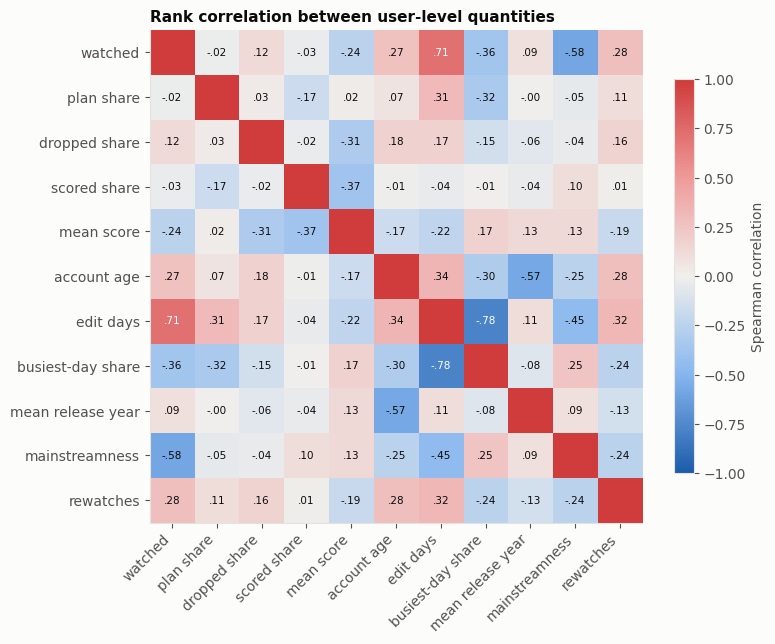

  -0.78  busiest-day share  ~  edit days
  +0.71  edit days  ~  watched
  -0.58  mainstreamness  ~  watched
  -0.57  mean release year  ~  account age
  -0.45  mainstreamness  ~  edit days
  -0.37  mean score  ~  scored share
  -0.36  busiest-day share  ~  watched
  +0.34  edit days  ~  account age


In [2]:
users = pl.read_parquet(config.CLEAN_USERS).drop("username").join(
    pl.read_parquet(config.USER_STATS), on="user_id", how="left")
u = (users.filter(pl.col("has_profile") & (pl.col("n_completed") + pl.col("n_watching") >= 20))
          .select(
              (pl.col("n_completed") + pl.col("n_watching")).alias("watched"),
              (pl.col("n_plan_to_watch") / pl.col("n_ratings")).alias("plan share"),
              (pl.col("n_dropped") / pl.col("n_ratings")).alias("dropped share"),
              (pl.col("n_scored") / (pl.col("n_ratings") - pl.col("n_plan_to_watch"))).alias("scored share"),
              pl.col("mean_score").alias("mean score"),
              ((pl.col("ratings_crawled_at").dt.date() - pl.col("joined")).dt.total_days() / 365.25).alias("account age"),
              pl.col("n_update_days").alias("edit days"),
              (pl.col("max_rows_per_day") / pl.col("n_ratings")).alias("busiest-day share"),
              pl.col("mean_start_year").alias("mean release year"),
              pl.col("mean_log_members").alias("mainstreamness"),
              pl.col("rewatched").alias("rewatches"),
          ).drop_nulls())
print(f"{u.height:,} users")
m = spearman(u)
heatmap(m, u.columns, "Rank correlation between user-level quantities")
strongest(m, u.columns)

Three patterns stand out. Bigger lists belong to users who edit on more days (+0.71) and whose
taste is less mainstream (-0.58 with the mean popularity of what they watch): heavy users dig
deeper into the catalog, so popularity bias hurts them most. Older accounts watch older anime
(-0.57 between account age and mean release year). And edit days against busiest-day share
(-0.78) is the bulk-edit pattern of the time notebook seen from another side. Scoring habits
are nearly independent of everything else, apart from a mild tendency for users who score more
of their list to give lower scores (-0.37).

## 2. Across anime

Anime with at least 200 rating rows and a MAL score.

17,443 anime


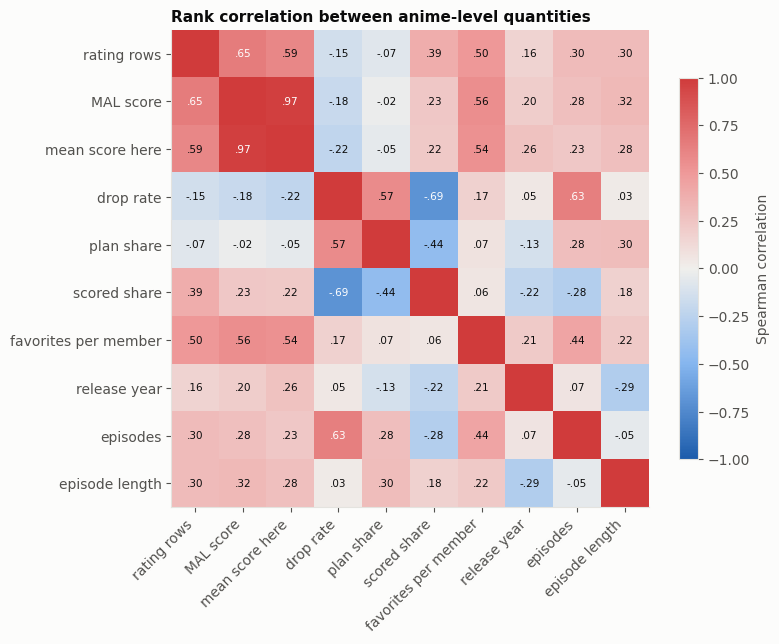

  +0.97  mean score here  ~  MAL score
  -0.69  scored share  ~  drop rate
  +0.65  MAL score  ~  rating rows
  +0.63  episodes  ~  drop rate
  +0.59  mean score here  ~  rating rows
  +0.57  plan share  ~  drop rate
  +0.56  favorites per member  ~  MAL score
  +0.54  favorites per member  ~  mean score here


In [3]:
anime = pl.read_parquet(config.CLEAN_ANIME)
stats = pl.read_parquet(config.TABLES / "anime_stats.parquet")
a = (anime.join(stats, on="anime_id").filter((pl.col("n_ratings") >= 200) & pl.col("score").is_not_null())
          .select(
              pl.col("n_ratings").alias("rating rows"),
              pl.col("score").alias("MAL score"),
              (pl.col("score_sum") / pl.col("n_scored")).alias("mean score here"),
              (pl.col("n_dropped") / (pl.col("n_dropped") + pl.col("n_completed"))).alias("drop rate"),
              (pl.col("n_plan_to_watch") / pl.col("n_ratings")).alias("plan share"),
              (pl.col("n_scored") / (pl.col("n_ratings") - pl.col("n_plan_to_watch"))).alias("scored share"),
              (pl.col("favorites") / pl.col("members")).alias("favorites per member"),
              pl.col("start_date").dt.year().alias("release year"),
              pl.col("episodes").alias("episodes"),
              pl.col("episode_minutes").alias("episode length"),
          ).drop_nulls())
print(f"{a.height:,} anime")
m = spearman(a)
heatmap(m, a.columns, "Rank correlation between anime-level quantities")
strongest(m, a.columns)

This dataset's mean score tracks MAL's (+0.97). Popular anime are scored higher (+0.65), drop
rate rises with the number of episodes (+0.63), and anime that are often dropped are also often
left in plan_to_watch (+0.57) and less often scored (-0.69). Favorites per member rises with
the score (+0.56) and is a cleaner sign of devotion than raw popularity.

## 3. Between genres

For each user, the share of watched anime in each genre. Two genres correlate positively
when the users who watch more of one also watch more of the other.

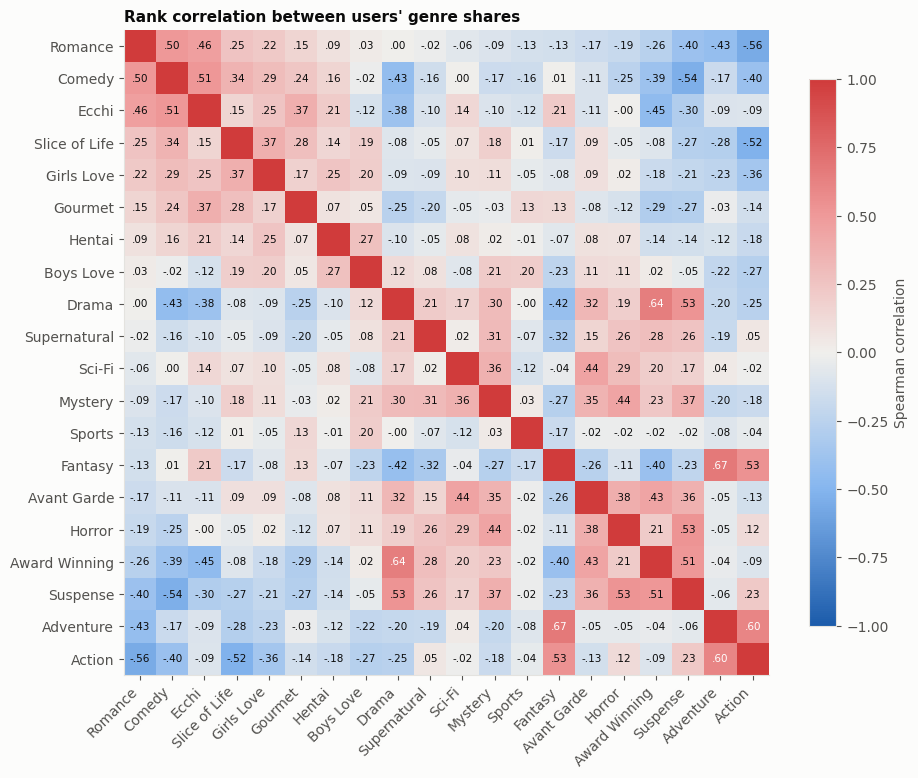

  +0.67  Fantasy  ~  Adventure
  +0.64  Award Winning  ~  Drama
  +0.60  Action  ~  Adventure
  -0.56  Action  ~  Romance
  -0.54  Comedy  ~  Suspense
  +0.53  Action  ~  Fantasy
  +0.53  Suspense  ~  Drama
  +0.53  Horror  ~  Suspense
  -0.52  Action  ~  Slice of Life
  +0.51  Ecchi  ~  Comedy


In [4]:
genre_cols = [c for c in users.columns if c.startswith("genre_")]
g = (users.filter(pl.col("n_completed") + pl.col("n_watching") >= 20)
          .select([(pl.col(c) / (pl.col("n_completed") + pl.col("n_watching"))).alias(c[6:]) for c in genre_cols]))
keep = [c for c in g.columns if g[c].mean() >= 0.005]
m = spearman(g.select(keep))
order = np.argsort(-m[keep.index("Romance")])
heatmap(m[np.ix_(order, order)], [keep[i] for i in order], "Rank correlation between users' genre shares",
        size=(9.5, 8))
strongest(m, keep, k=10)

Genre shares form two loose blocks. Action, Adventure and Fantasy rise together (+0.5 to +0.7)
and are negatively related to Romance and Slice of Life (about -0.5). Drama, Suspense, Horror,
Mystery and Award Winning form another group. Part of the negative correlation is mechanical,
since shares compete for the same list. Even so, the blocks are a reasonable low-dimensional
picture of taste.

## 4. Between pairs of anime

Among the 200 anime with the most members: how often two anime are watched by the same
user. Similarity is the Jaccard index, `both / (either)`.

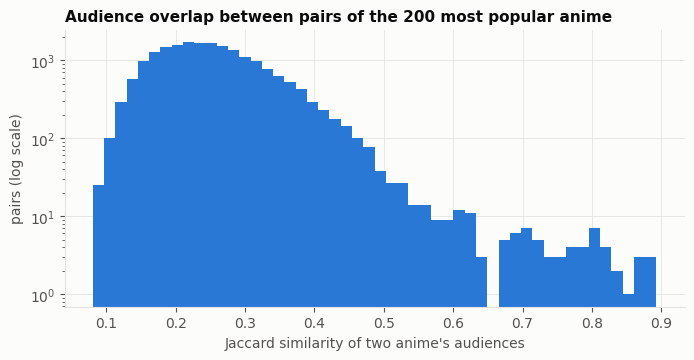

median Jaccard 0.246, 99th percentile 0.494

most similar pairs:
  0.89  Shingeki no Kyojin Season 3 Part 2          ~  Shingeki no Kyojin Season 3
  0.88  Overlord III                                ~  Overlord II
  0.88  Shingeki no Kyojin Season 3                 ~  Shingeki no Kyojin Season 2
  0.87  Boku no Hero Academia 3rd Season            ~  Boku no Hero Academia 2nd Season
  0.87  JoJo no Kimyou na Bouken Part 3: Stardust   ~  JoJo no Kimyou na Bouken Part 3: Stardust 
  0.86  Boku no Hero Academia 2nd Season            ~  Boku no Hero Academia
  0.84  Haikyuu!! Karasuno Koukou vs. Shiratorizaw  ~  Haikyuu!! Second Season
  0.84  JoJo no Kimyou na Bouken Part 3: Stardust   ~  JoJo no Kimyou na Bouken Part 4: Diamond w
  0.83  JoJo no Kimyou na Bouken Part 5: Ougon no   ~  JoJo no Kimyou na Bouken Part 4: Diamond w
  0.82  Fate/Zero 2nd Season                        ~  Fate/Zero
  0.82  Code Geass: Hangyaku no Lelouch R2          ~  Code Geass: Hangyaku no Lelouch
  0.82  JoJo

In [5]:
co = np.load(config.TABLES / "cooccurrence.npz")
counts, ids = co["counts"].astype(float), co["anime_id"]
title = dict(anime.select("anime_id", "title").iter_rows())
names = [title[i] for i in ids]
n = np.diag(counts)
jaccard = counts / (n[:, None] + n[None, :] - counts)
np.fill_diagonal(jaccard, np.nan)
upper = jaccard[np.triu_indices(len(ids), 1)]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(upper, bins=50, color=BLUE)
ax.set_yscale("log")
ax.set_xlabel("Jaccard similarity of two anime's audiences"); ax.set_ylabel("pairs (log scale)")
ax.set_title("Audience overlap between pairs of the 200 most popular anime")
plt.show()
print(f"median Jaccard {np.median(upper):.3f}, 99th percentile {np.quantile(upper, 0.99):.3f}")

pairs = sorted(((jaccard[i, j], names[i], names[j]) for i in range(len(ids)) for j in range(i)), reverse=True)
print("\nmost similar pairs:")
for sim, x, y in pairs[:15]:
    print(f"  {sim:.2f}  {x[:42]:42s}  ~  {y[:42]}")

In [6]:
def neighbours(name, k=6):
    i = names.index(name)
    best = np.argsort(-np.nan_to_num(jaccard[i]))[:k]
    print(f"{name}:")
    for j in best:
        print(f"    {jaccard[i, j]:.2f}  {names[j]}")


for seed in ("Shingeki no Kyojin", "Sen to Chihiro no Kamikakushi", "Kimetsu no Yaiba", "Steins;Gate"):
    if seed in names:
        neighbours(seed)

Shingeki no Kyojin:
    0.80  Shingeki no Kyojin Season 2
    0.73  Shingeki no Kyojin Season 3
    0.69  Shingeki no Kyojin Season 3 Part 2
    0.63  Kimetsu no Yaiba
    0.62  Death Note
    0.62  One Punch Man
Sen to Chihiro no Kamikakushi:
    0.56  Howl no Ugoku Shiro
    0.49  Mononoke Hime
    0.47  Tonari no Totoro
    0.43  Kimi no Na wa.
    0.40  Koe no Katachi
    0.39  Shingeki no Kyojin
Kimetsu no Yaiba:
    0.69  Jujutsu Kaisen
    0.63  Shingeki no Kyojin
    0.62  Kimetsu no Yaiba: Yuukaku-hen
    0.62  Shingeki no Kyojin Season 2
    0.61  Shingeki no Kyojin Season 3
    0.61  Boku no Hero Academia
Steins;Gate:
    0.45  Code Geass: Hangyaku no Lelouch
    0.45  Fullmetal Alchemist: Brotherhood
    0.44  Re:Zero kara Hajimeru Isekai Seikatsu
    0.43  Code Geass: Hangyaku no Lelouch R2
    0.43  Boku dake ga Inai Machi
    0.43  Shingeki no Kyojin


Even among the 200 most popular anime, the typical pair shares a quarter of its audience
(median Jaccard 0.25), which is popularity rather than taste. The pairs that stand out are
almost all consecutive seasons of one franchise (0.8 to 0.9): the strongest signal in
co-watching data is "watched season 1, then season 2". Beyond franchises, neighbours follow era
and audience (Spirited Away sits with other Ghibli films and Your Name, Demon Slayer with
Jujutsu Kaisen). An item-to-item model picks this structure up directly, and a model evaluated
on a random hold-out gets much of its score from sequels.